In [5]:
%pip install seaborn


  Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip available: 22.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/creditcard.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [7]:
print("Dataset Shape:", df.shape)
print("\nDataset Info:")
df.info()

Dataset Shape: (284807, 31)

Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 n

In [8]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nClass distribution:")
print(df["Class"].value_counts())

print("\nClass percentage:")
print((df["Class"].value_counts(normalize=True) * 100).round(4))

Missing values: 0
Duplicate rows: 1081

Class distribution:
Class
0    284315
1       492
Name: count, dtype: int64

Class percentage:
Class
0    99.8273
1     0.1727
Name: proportion, dtype: float64


In [9]:
df = df.drop_duplicates().reset_index(drop=True)

print("Shape after removing duplicates:", df.shape)
print("Remaining duplicates:", df.duplicated().sum())
print("\nClass distribution:")
print(df["Class"].value_counts())

Shape after removing duplicates: (283726, 31)
Remaining duplicates: 0

Class distribution:
Class
0    283253
1       473
Name: count, dtype: int64


In [10]:
X = df.drop("Class", axis=1)
y = df["Class"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (283726, 30)
Target shape: (283726,)


In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

print("\nFraud distribution in training set:")
print(y_train.value_counts())

print("\nFraud distribution in testing set:")
print(y_test.value_counts())

Training set: (226980, 30)
Testing set: (56746, 30)

Fraud distribution in training set:
Class
0    226602
1       378
Name: count, dtype: int64

Fraud distribution in testing set:
Class
0    56651
1       95
Name: count, dtype: int64


In [12]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, balanced_accuracy_score,
    confusion_matrix, classification_report
)
import time

In [13]:
rf = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

start = time.time()
rf.fit(X_train, y_train)
rf_train_time = time.time() - start

rf_pred = rf.predict(X_test)
rf_prob = rf.predict_proba(X_test)[:, 1]

print("Random Forest Baseline")
print("Training time:", round(rf_train_time, 2), "seconds")
print("Precision:", precision_score(y_test, rf_pred))
print("Recall:", recall_score(y_test, rf_pred))
print("F1:", f1_score(y_test, rf_pred))
print("ROC-AUC:", roc_auc_score(y_test, rf_prob))
print("Average Precision:", average_precision_score(y_test, rf_prob))
print("Balanced Accuracy:", balanced_accuracy_score(y_test, rf_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, rf_pred))

Random Forest Baseline
Training time: 52.62 seconds
Precision: 0.9583333333333334
Recall: 0.7263157894736842
F1: 0.8263473053892215
ROC-AUC: 0.947420076200634
Average Precision: 0.8033339313357926
Balanced Accuracy: 0.8631314168282438

Confusion Matrix:
 [[56648     3]
 [   26    69]]


In [14]:
fraud_count = (y_train == 1).sum()
legit_count = (y_train == 0).sum()

xgb = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.1,
    scale_pos_weight=legit_count / fraud_count,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

start = time.time()
xgb.fit(X_train, y_train)
xgb_train_time = time.time() - start

xgb_pred = xgb.predict(X_test)
xgb_prob = xgb.predict_proba(X_test)[:, 1]

print("XGBoost Baseline")
print("Training time:", round(xgb_train_time, 2), "seconds")
print("Precision:", precision_score(y_test, xgb_pred))
print("Recall:", recall_score(y_test, xgb_pred))
print("F1:", f1_score(y_test, xgb_pred))
print("ROC-AUC:", roc_auc_score(y_test, xgb_prob))
print("Average Precision:", average_precision_score(y_test, xgb_prob))
print("Balanced Accuracy:", balanced_accuracy_score(y_test, xgb_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, xgb_pred))

XGBoost Baseline
Training time: 4.64 seconds
Precision: 0.9146341463414634
Recall: 0.7894736842105263
F1: 0.847457627118644
ROC-AUC: 0.9749932411654367
Average Precision: 0.8139115802985374
Balanced Accuracy: 0.8946750603185338

Confusion Matrix:
 [[56644     7]
 [   20    75]]


In [15]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

scoring = {
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "average_precision": "average_precision"
}

In [16]:
rf_cv_results = cross_validate(
    rf,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1,
    return_train_score=False
)

print("Random Forest Cross-Validation Results\n")

for metric in scoring:
    scores = rf_cv_results[f"test_{metric}"]
    print(f"{metric}: {scores.mean():.4f} ± {scores.std():.4f}")

Random Forest Cross-Validation Results

precision: 0.9208 ± 0.0307
recall: 0.7937 ± 0.0425
f1: 0.8519 ± 0.0301
roc_auc: 0.9619 ± 0.0121
average_precision: 0.8299 ± 0.0197


In [17]:
xgb_cv_results = cross_validate(
    xgb,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1,
    return_train_score=False
)

print("XGBoost Cross-Validation Results\n")

for metric in scoring:
    scores = xgb_cv_results[f"test_{metric}"]
    print(f"{metric}: {scores.mean():.4f} ± {scores.std():.4f}")

XGBoost Cross-Validation Results

precision: 0.8928 ± 0.0296
recall: 0.8228 ± 0.0357
f1: 0.8554 ± 0.0158
roc_auc: 0.9794 ± 0.0053
average_precision: 0.8477 ± 0.0216


In [18]:
from sklearn.model_selection import RandomizedSearchCV

rf_param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
    "max_features": ["sqrt", 0.5],
    "class_weight": ["balanced", "balanced_subsample"]
}

rf_random = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=42, n_jobs=-1),
    param_distributions=rf_param_grid,
    n_iter=10,
    scoring="average_precision",
    cv=cv,
    verbose=1,
    random_state=42,
    n_jobs=1
)

rf_random.fit(X_train, y_train)

print("Best Random Forest Parameters:")
print(rf_random.best_params_)

print("\nBest CV Average Precision:")
print(rf_random.best_score_)

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best Random Forest Parameters:
{'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 20, 'class_weight': 'balanced'}

Best CV Average Precision:
0.8327591521226728


In [19]:
from xgboost import XGBClassifier

xgb_param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 4, 5, 6],
    "learning_rate": [0.01, 0.05, 0.1],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0],
    "min_child_weight": [1, 3, 5],
    "gamma": [0, 0.1, 0.3],
    "reg_alpha": [0, 0.1, 1],
    "reg_lambda": [1, 5, 10]
}

xgb_random = RandomizedSearchCV(
    estimator=XGBClassifier(
        scale_pos_weight=legit_count / fraud_count,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ),
    param_distributions=xgb_param_grid,
    n_iter=10,
    scoring="average_precision",
    cv=cv,
    verbose=1,
    random_state=42,
    n_jobs=1
)

xgb_random.fit(X_train, y_train)

print("Best XGBoost Parameters:")
print(xgb_random.best_params_)

print("\nBest CV Average Precision:")
print(xgb_random.best_score_)

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best XGBoost Parameters:
{'subsample': 0.8, 'reg_lambda': 5, 'reg_alpha': 0.1, 'n_estimators': 300, 'min_child_weight': 1, 'max_depth': 4, 'learning_rate': 0.1, 'gamma': 0.3, 'colsample_bytree': 0.8}

Best CV Average Precision:
0.8502295973830617


In [20]:
best_rf = rf_random.best_estimator_
best_xgb = xgb_random.best_estimator_

In [24]:
def evaluate_model(model, X_test, y_test, model_name):

    start = time.time()

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    print(f"\n{model_name}")
    print("-" * 40)

    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Precision:", precision_score(y_test, y_pred))
    print("Recall:", recall_score(y_test, y_pred))
    print("F1 Score:", f1_score(y_test, y_pred))
    print("ROC-AUC:", roc_auc_score(y_test, y_prob))
    print("Average Precision:", average_precision_score(y_test, y_prob))
    print("Balanced Accuracy:", balanced_accuracy_score(y_test, y_pred))

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, y_pred))

    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))

    return {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "Average Precision": average_precision_score(y_test, y_prob),
        "Balanced Accuracy": balanced_accuracy_score(y_test, y_pred)
    }

In [22]:
rf_results = evaluate_model(
    best_rf, X_test, y_test, "Tuned Random Forest"
)

xgb_results = evaluate_model(
    best_xgb, X_test, y_test, "Tuned XGBoost"
)


Tuned Random Forest
----------------------------------------
Accuracy: 0.9994713283755683
Precision: 0.9333333333333333
Recall: 0.7368421052631579
F1 Score: 0.8235294117647058
ROC-AUC: 0.9551577572375272
Average Precision: 0.8176626523413849
Balanced Accuracy: 0.8683769227839151

Confusion Matrix:
[[56646     5]
 [   25    70]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.93      0.74      0.82        95

    accuracy                           1.00     56746
   macro avg       0.97      0.87      0.91     56746
weighted avg       1.00      1.00      1.00     56746


Tuned XGBoost
----------------------------------------
Accuracy: 0.9995065731505305
Precision: 0.9036144578313253
Recall: 0.7894736842105263
F1 Score: 0.8426966292134831
ROC-AUC: 0.9770524792148417
Average Precision: 0.819500533821322
Balanced Accuracy: 0.8946662343490012

Confusion Matrix:
[[56643     8]
 [   20   

In [23]:
comparison = pd.DataFrame({
    "Random Forest": rf_results,
    "XGBoost": xgb_results
})

display(comparison)

,Random Forest,XGBoost
Accuracy,0.999471,0.999507
Precision,0.933333,0.903614
Recall,0.736842,0.789474
F1 Score,0.823529,0.842697
ROC-AUC,0.955158,0.977052
Average Precision,0.817663,0.819501
Balanced Accuracy,0.868377,0.894666


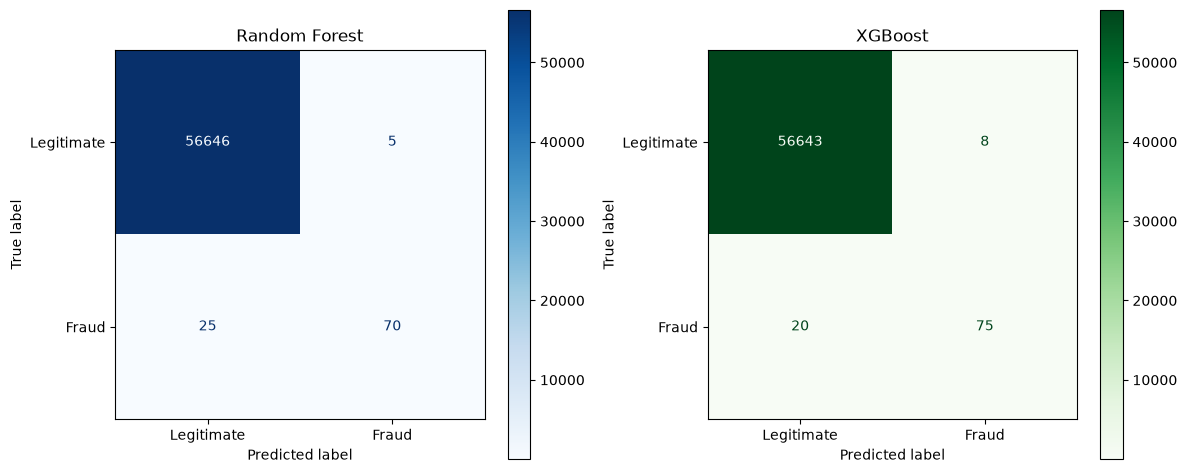

In [25]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_estimator(
    best_rf, X_test, y_test,
    display_labels=["Legitimate", "Fraud"],
    cmap="Blues",
    ax=axes[0]
)
axes[0].set_title("Random Forest")

ConfusionMatrixDisplay.from_estimator(
    best_xgb, X_test, y_test,
    display_labels=["Legitimate", "Fraud"],
    cmap="Greens",
    ax=axes[1]
)
axes[1].set_title("XGBoost")

plt.tight_layout()
plt.show()

<Figure size 800x600 with 0 Axes>

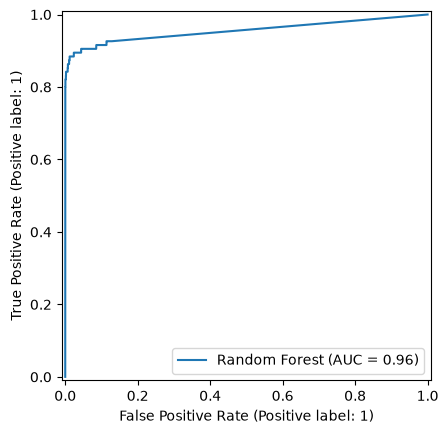

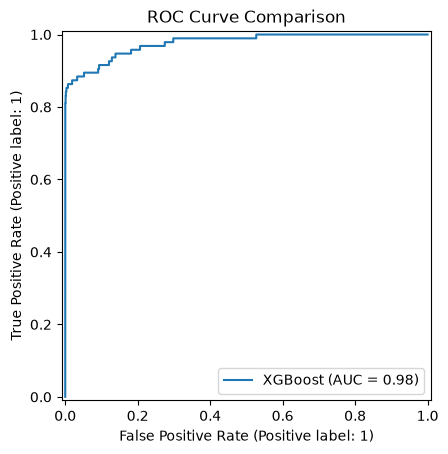

In [26]:
from sklearn.metrics import RocCurveDisplay

plt.figure(figsize=(8, 6))

RocCurveDisplay.from_estimator(best_rf, X_test, y_test, name="Random Forest")
RocCurveDisplay.from_estimator(best_xgb, X_test, y_test, name="XGBoost")

plt.title("ROC Curve Comparison")
plt.show()

<Figure size 800x600 with 0 Axes>

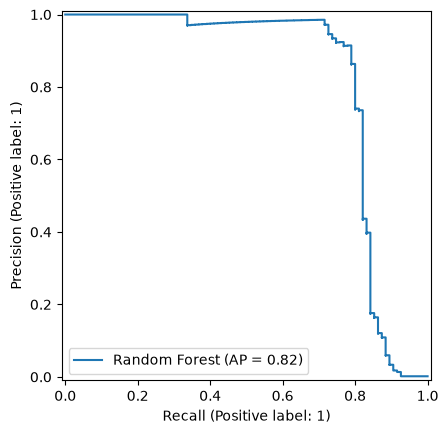

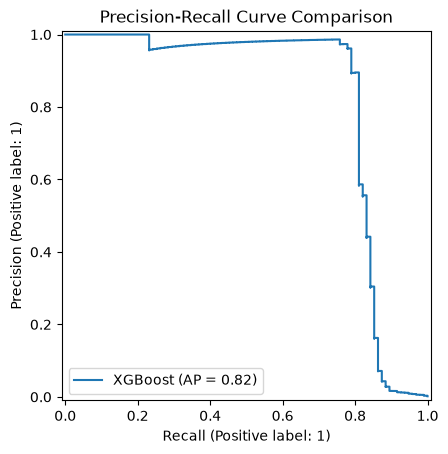

In [27]:
from sklearn.metrics import PrecisionRecallDisplay

plt.figure(figsize=(8, 6))

PrecisionRecallDisplay.from_estimator(
    best_rf, X_test, y_test, name="Random Forest"
)

PrecisionRecallDisplay.from_estimator(
    best_xgb, X_test, y_test, name="XGBoost"
)

plt.title("Precision-Recall Curve Comparison")
plt.show()

In [28]:
y_prob = best_xgb.predict_proba(X_test)[:, 1]

print("Prediction probabilities generated.")

Prediction probabilities generated.


In [29]:
from sklearn.metrics import precision_score, recall_score, f1_score, fbeta_score

thresholds = [0.5, 0.4, 0.3, 0.2, 0.1, 0.05]

threshold_results = []

for threshold in thresholds:

    y_pred = (y_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred),
        "F2 Score": fbeta_score(y_test, y_pred, beta=2)
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Threshold,Precision,Recall,F1 Score,F2 Score
0,0.50,0.9036,0.7895,0.8427,0.8099
1,0.40,0.8851,0.8105,0.8462,0.8244
2,0.30,0.8021,0.8105,0.8063,0.8088
3,0.20,0.7549,0.8105,0.7817,0.7988
4,0.10,0.5969,0.8105,0.6875,0.7564
5,0.05,0.4540,0.8316,0.5874,0.7130


In [30]:
import joblib
import json
import os

os.makedirs("../models", exist_ok=True)

# Save tuned XGBoost model
joblib.dump(best_xgb, "../models/xgboost.pkl")

# Save feature names and prediction threshold
metadata = {
    "feature_names": X.columns.tolist(),
    "threshold": 0.40
}

with open("../models/model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)

print("XGBoost model saved successfully!")
print("Model: ../models/xgboost.pkl")
print("Metadata: ../models/model_metadata.json")

XGBoost model saved successfully!
Model: ../models/xgboost.pkl
Metadata: ../models/model_metadata.json


In [31]:
# Create a CSV containing held-out transactions without actual labels

unseen_data = X_test.copy()

# Save CSV
unseen_data.to_csv(
    "../data/unseen_transactions.csv",
    index=False
)

print("Unseen transaction CSV created successfully!")
print("Total transactions:", len(unseen_data))
print("Features:", unseen_data.shape[1])
print("Class column present:", "Class" in unseen_data.columns)

Unseen transaction CSV created successfully!
Total transactions: 56746
Features: 30
Class column present: False


In [32]:
test_data = X_test.copy()
test_data["Class"] = y_test

test_data.to_csv(
    "../data/test_transactions_labeled.csv",
    index=False
)

print("Labeled test dataset saved!")

Labeled test dataset saved!


In [40]:
import shap
import matplotlib.pyplot as plt

print("SHAP version:", shap.__version__)

SHAP version: 0.51.0


In [41]:
explainer = shap.TreeExplainer(best_xgb) #best_xgb is out tuned xgboost model

print("TreeSHAP explainer created successfully!")

TreeSHAP explainer created successfully!


In [42]:
# Select 1,000 test transactions
X_sample = X_test.sample(n=1000, random_state=42)

# Calculate SHAP values
shap_values = explainer(X_sample)

print("SHAP values calculated successfully!")
print("SHAP values shape:", shap_values.values.shape)

SHAP values calculated successfully!
SHAP values shape: (1000, 30)


X_test.sample() selects 1,000 transactions from our test dataset.



explainer(X_sample) calculates the contribution of every feature to every selected prediction.



shap_values.values.shape shows the dimensions of the resulting SHAP values.

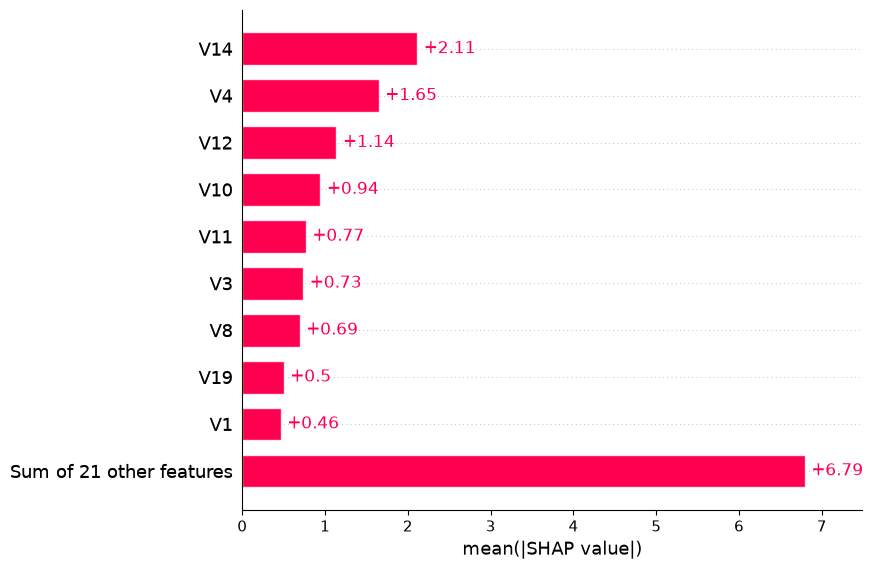

In [43]:
shap.plots.bar(shap_values)

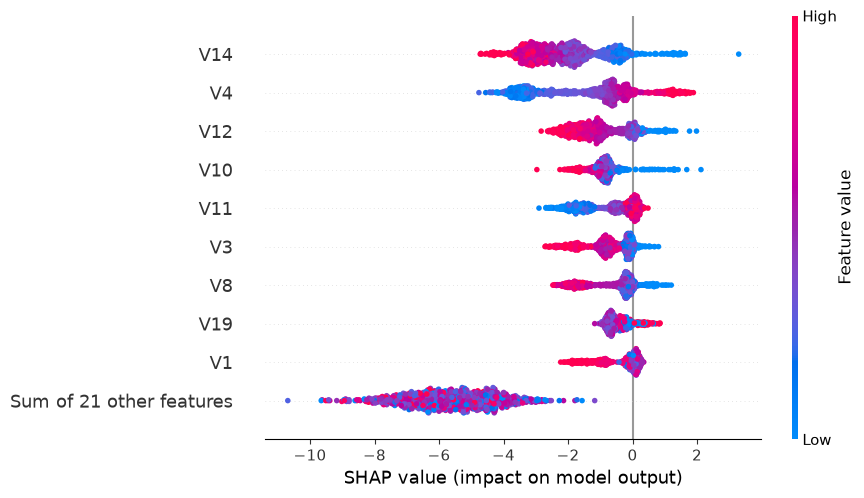

In [44]:
shap.plots.beeswarm(shap_values)

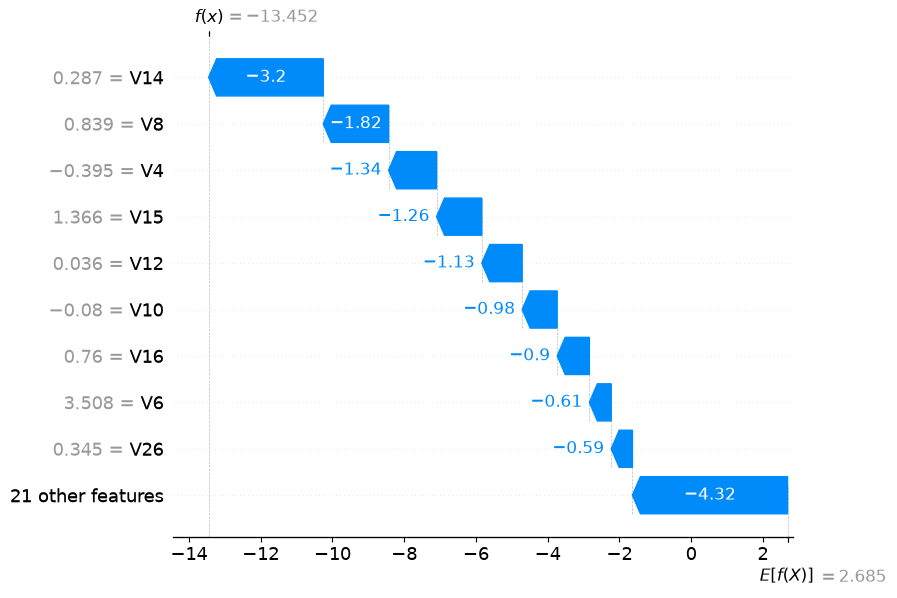

In [45]:
# Select the first transaction from our SHAP sample
transaction = X_sample.iloc[[0]]

# Get the actual SHAP explanation
shap.plots.waterfall(shap_values[0])

In [46]:
fraud_probability = best_xgb.predict_proba(transaction)[0][1]

predicted_class = (
    "Fraud" if fraud_probability >= 0.4
    else "Legitimate"
)

print("Fraud Probability:", fraud_probability)
print("Predicted Class:", predicted_class)

Fraud Probability: 1.4382766e-06
Predicted Class: Legitimate


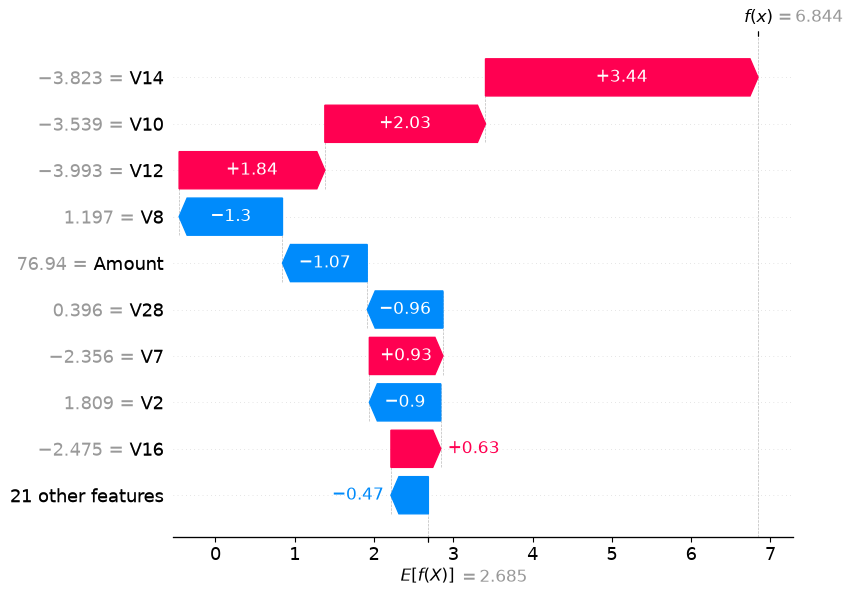

In [47]:
# Find a fraudulent transaction in the test set
fraud_indices = y_test[y_test == 1].index

# Select one fraudulent transaction
fraud_transaction = X_test.loc[[fraud_indices[0]]]

# Calculate its SHAP explanation
fraud_shap = explainer(fraud_transaction)

# Display waterfall plot
shap.plots.waterfall(fraud_shap[0])